# Lecture 13 — AE catalogue analysis

This notebook connects an acoustic-emission (AE) catalogue to the mechanical experiment. It is written as a linear workflow: run the cells from top to bottom after editing the settings cell.

## Learning goals

By the end, you should be able to:

1. load the mechanical file and the catalogue exported by the AE analyzer;
2. locate every analyzed waveform window on the mechanical record;
3. calculate AE rate independently for every recording window and channel;
4. choose a separate rate-bin width $\Delta t$ for each window–channel pair;
5. compare mechanical data, AE rate, amplitude, and an amplitude-based b-value proxy.

> A detection on several sensors is not necessarily several physical sources. Channels are therefore kept separate throughout the notebook.


## 1. Imports


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})


## 2. Settings — edit this cell

Place both data files beside the notebook or enter full paths. `CHANNELS = "all"` uses every analyzed channel (from 1 to 32).

For a legacy catalogue, rows exist only for chunks containing candidates. To include analyzed chunks containing zero candidates, replace `"infer"` in `LEGACY_ANALYSED_CHUNKS` with an explicit list. The `recording_start_chunk` identifies the start of the physical recording; it does **not** need to equal the first chunk selected for analysis.

`RATE_BIN_OVERRIDES` provides reproducible, pair-specific $\Delta t$ values. The interactive controls in Point 6 can change the same values during a lesson.


In [3]:
# ---------- Input files ----------
MECHANICAL_FILE = Path("../s0020sa03F11040/s0020sa03F11040_reduced_data.npz")
CATALOG_FILE = Path("../ae_channel_catalog.csv")

# ---------- Acquisition information ----------
MECHANICAL_SAMPLING_RATE_HZ = 1_000.0  # used only if the file has no time column
MECHANICAL_TIME_COLUMN = "time_s"       # set to None to auto-detect a time column
AE_SAMPLING_RATE_HZ = 1_000_000.0      # waveform sampling rate [Hz]
CHUNK_DURATION_S = 1.0                 # duration of one waveform chunk [s]
WINDOW_ANCHOR_TOLERANCE_S = 0.01       # groups legacy rows into recording windows

# ---------- Legacy-catalogue exposure ----------
# Example for two physical recording windows:
# LEGACY_ANALYSED_CHUNKS = [
#     {"name": "window1", "window_start_s": 2663.45,
#      "recording_start_chunk": 0, "channels": [2], "chunks": [4, 5, 6, 17]},
#     {"name": "window2", "window_start_s": 3100.20,
#      "recording_start_chunk": 0, "channels": [1, 2, 3], "chunks": list(range(0, 8))},
# ]
LEGACY_ANALYSED_CHUNKS = "infer"

# ---------- Channels and default mechanical axes ----------
CHANNELS = "all"                       # or [1, 2, 3]
DEFAULT_X_AXIS = "time_s"              # or a numerical mechanical column
DEFAULT_MECHANICAL_Y = "axial_stress_MPa"
MAX_CHANNELS_AS_CURVES = 8

# ---------- AE-rate settings ----------
DEFAULT_RATE_BIN_S = 1.0
# Keys may use a window name or index. Examples:
# RATE_BIN_OVERRIDES = {("window1", 2): 0.25, (1, 4): 2.0}
RATE_BIN_OVERRIDES = {}

# ---------- Amplitude and b-value proxy ----------
AMPLITUDE_REFERENCE = 1.0
MAGNITUDE_BIN = 0.10
MIN_EVENTS_FOR_B = 20
B_VALUE_CHANNEL = None                  # None selects the first available channel
ROLLING_EVENTS = 100
ROLLING_STEP = 25


## 3. Load the mechanical file

The loader accepts NPZ, NPY, CSV, tab-separated, and whitespace-separated files. It also detects the common two-row text format in which column names are followed by physical units. Non-numeric columns are ignored, and rows without a valid time are removed.

Object-valued NPZ files require `allow_pickle=True`; open them only when you trust their source.


In [4]:
def _fields_are_numeric(fields):
    # Return True when every non-empty field can be converted to a number.
    try:
        values = [value for value in fields if str(value).strip()]
        return bool(values) and all(np.isfinite(float(value)) for value in values)
    except (TypeError, ValueError):
        return False


def _load_text_table(path):
    # Read a delimited text table, including an optional second units row.
    with Path(path).open("rt", encoding="utf-8-sig", errors="replace") as handle:
        first_line = handle.readline().rstrip("\r\n")
        second_line = handle.readline().rstrip("\r\n")

    if not first_line.strip():
        raise ValueError("The mechanical file is empty.")

    separator = "\t" if "\t" in first_line else "," if "," in first_line else r"\s+"
    splitter = (lambda line: line.split(separator)) if separator != r"\s+" else (lambda line: line.split())
    first_is_numeric = _fields_are_numeric(splitter(first_line))
    second_is_numeric = _fields_are_numeric(splitter(second_line))

    if first_is_numeric:
        table = pd.read_csv(path, sep=separator, engine="python", header=None, comment="#")
        table.columns = [f"column_{index + 1}" for index in range(table.shape[1])]
    else:
        skiprows = [1] if second_line and not second_is_numeric else None
        table = pd.read_csv(path, sep=separator, engine="python", header=0,
                            skiprows=skiprows, comment="#")

    table.columns = [str(column).strip() for column in table.columns]
    numeric = table.apply(pd.to_numeric, errors="coerce")
    numeric = numeric.loc[:, numeric.notna().any(axis=0)]
    if numeric.empty:
        raise ValueError("The mechanical file contains no numerical columns.")
    return numeric


def load_mechanical(path):
    # Return the reduced mechanical data as a numerical DataFrame.
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Mechanical file not found: {path.resolve()}")

    suffix = path.suffix.lower()
    if suffix == ".npz":
        with np.load(path, allow_pickle=True) as archive:
            if len(archive.files) == 1:
                value = archive[archive.files[0]]
                if value.dtype == object and value.shape == ():
                    value = value.item()
                    if isinstance(value, dict):
                        return pd.DataFrame({name: np.asarray(column) for name, column in value.items()})
            arrays = {name: np.asarray(archive[name]) for name in archive.files}
            if arrays and all(array.ndim == 1 for array in arrays.values()):
                return pd.DataFrame(arrays)
            if len(arrays) == 1:
                array = next(iter(arrays.values()))
                if array.ndim in (1, 2):
                    return pd.DataFrame(array)
        raise ValueError("The NPZ structure is not a table of mechanical channels.")

    if suffix == ".npy":
        return pd.DataFrame(np.load(path, allow_pickle=False))

    return _load_text_table(path)


mechanical = load_mechanical(MECHANICAL_FILE)
mechanical.columns = [str(name).strip() for name in mechanical.columns]

# Prefer an explicitly named time column. Otherwise reconstruct time from row number.
time_aliases = {"time", "time_s", "time (s)", "time [s]", "mechanical_time"}
if MECHANICAL_TIME_COLUMN is not None and MECHANICAL_TIME_COLUMN not in mechanical.columns:
    raise ValueError(
        f"MECHANICAL_TIME_COLUMN={MECHANICAL_TIME_COLUMN!r} is unavailable. "
        f"Choose from {list(mechanical.columns)} or use None."
    )
time_columns = ([MECHANICAL_TIME_COLUMN] if MECHANICAL_TIME_COLUMN is not None else
                [name for name in mechanical.columns if name.strip().lower() in time_aliases])
if time_columns:
    source_time_column = time_columns[0]
    mechanical_time = pd.to_numeric(mechanical[source_time_column], errors="coerce").to_numpy(float)
else:
    source_time_column = "time_s"
    mechanical_time = np.arange(len(mechanical), dtype=float) / MECHANICAL_SAMPLING_RATE_HZ
    mechanical.insert(0, source_time_column, mechanical_time)

# Remove a malformed row rather than allowing it to corrupt every later calculation.
valid_time = np.isfinite(mechanical_time)
mechanical = mechanical.loc[valid_time].reset_index(drop=True)
mechanical_time = mechanical_time[valid_time]

if len(mechanical_time) < 2 or np.any(np.diff(mechanical_time) <= 0):
    raise ValueError("Mechanical time must contain at least two finite, strictly increasing values.")

print(f"Loaded {len(mechanical):,} mechanical rows")
print(f"Experiment time: {mechanical_time[0]:.3f} to {mechanical_time[-1]:.3f} s")
print("Numerical columns:", list(mechanical.columns))
mechanical.head()


Loaded 73,477 mechanical rows
Experiment time: 0.000 to 3690.000 s
Numerical columns: ['shear_stress_MPa', 'lp_disp_mm', 'ec_disp_mm', 'normal_stress_MPa', 'lt_disp_mm1', 'lt_ec_mm1', 'rgt_lt_mm', 'friction_na', 'shear_strain_na', 'time_s', 'records_na']


,shear_stress_MPa,lp_disp_mm,ec_disp_mm,normal_stress_MPa,lt_disp_mm1,lt_ec_mm1,rgt_lt_mm,friction_na,shear_strain_na,time_s,records_na
0,0.0,-0.0,0.0,1.000000e-07,3.0,4.601790,4.601790,0.0,0.0,0.0,0
1,0.0,-0.0,0.0,1.000000e-07,3.0,4.595871,4.601790,0.0,0.0,1.0,1
2,0.0,-0.0,0.0,1.000000e-07,3.0,4.586738,4.595871,0.0,0.0,2.0,2
3,0.0,-0.0,0.0,1.000000e-07,3.0,4.577800,4.586738,0.0,0.0,3.0,3
4,0.0,-0.0,0.0,1.000000e-07,3.0,4.569084,4.577800,0.0,0.0,4.0,4


### Checkpoint 1

Confirm that the experiment duration and column names are plausible before continuing.


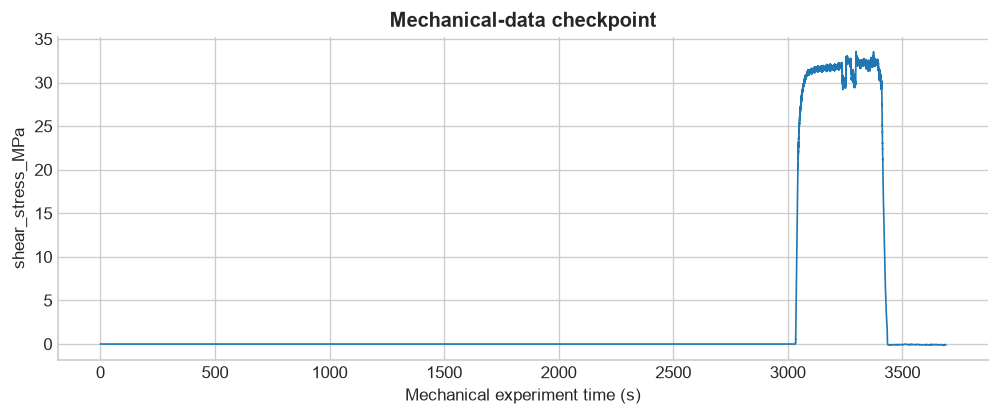

In [5]:
fig, axis = plt.subplots(figsize=(10, 3.5))
preview_column = (DEFAULT_MECHANICAL_Y if DEFAULT_MECHANICAL_Y in mechanical.columns
                  else next(name for name in mechanical.columns if name != source_time_column))
axis.plot(mechanical_time, pd.to_numeric(mechanical[preview_column], errors="coerce"), lw=1)
axis.set(xlabel="Mechanical experiment time (s)", ylabel=preview_column,
         title="Mechanical-data checkpoint")
plt.show()


## 4. Load the catalogue and reconstruct analyzed chunks

The notebook distinguishes a physical recording window, a chunk inside that window, and the subset of window–channel–chunk combinations actually analyzed. The resulting `exposure` table contains one row per analyzed combination.

For a legacy catalogue, the physical window start is reconstructed from each event:

$$t_{window}=t_{event}-(chunk-recording\ start\ chunk)\,\Delta t_{chunk}
-\frac{sample\ in\ chunk}{f_{AE}}.$$

The newer catalogue format can instead provide explicit `row_type = "analysis"` rows, including chunks with zero detected candidates.


In [6]:
def parse_boolean(series, column_name="accepted"):
    # Convert common text and numerical Boolean representations.
    text = series.astype(str).str.strip().str.lower()
    mapping = {"true": True, "false": False, "yes": True, "no": False,
               "1": True, "0": False, "1.0": True, "0.0": False}
    invalid = ~text.isin(mapping)
    if invalid.any():
        raise ValueError(f"Unrecognized values in {column_name}: {sorted(text[invalid].unique())}")
    return text.map(mapping).astype(bool)


def cluster_window_anchors(values, tolerance_s):
    # Assign nearly equal legacy anchor estimates to the same physical window.
    values = np.asarray(values, dtype=float)
    order = np.argsort(values)
    labels = np.empty(len(values), dtype=int)
    groups = []
    centers = []
    for position in order:
        value = values[position]
        if not centers or abs(value - centers[-1]) > tolerance_s:
            groups.append([value])
        else:
            groups[-1].append(value)
        centers = [float(np.median(group)) for group in groups]
        labels[position] = len(groups) - 1
    return labels, np.asarray(centers, dtype=float)


if not CATALOG_FILE.exists():
    raise FileNotFoundError(f"Catalogue not found: {CATALOG_FILE.resolve()}")

catalog = pd.read_csv(CATALOG_FILE)
catalog.columns = [str(column).strip() for column in catalog.columns]
is_updated_catalogue = "row_type" in catalog.columns

if is_updated_catalogue:
    row_type = catalog["row_type"].astype(str).str.strip().str.lower()
    events = catalog[row_type.eq("event")].copy()
    manifest = catalog[row_type.isin(["analysis", "exposure"])].copy()
else:
    events = catalog.copy()
    manifest = pd.DataFrame()

required_event_columns = {
    "recording_start_chunk", "channel", "chunk", "sample_in_chunk",
    "onset_s", "peak_to_peak", "accepted",
}
missing = required_event_columns.difference(events.columns)
if missing:
    raise ValueError(f"Catalogue is missing required event columns: {sorted(missing)}")

for column in ["recording_start_chunk", "channel", "chunk", "sample_in_chunk"]:
    events[column] = pd.to_numeric(events[column], errors="raise").astype(int)
for column in ["onset_s", "peak_to_peak"]:
    events[column] = pd.to_numeric(events[column], errors="raise")
events["accepted"] = parse_boolean(events["accepted"])

exposure_rows = []

if is_updated_catalogue:
    required_manifest = {"window_index", "window", "window_start_s", "channel"}
    missing = required_manifest.difference(manifest.columns)
    if missing or manifest.empty:
        raise ValueError("Updated catalogue has no usable analysis/exposure rows: " + str(sorted(missing)))

    for column in ["window_index", "recording_start_chunk", "channel"]:
        manifest[column] = pd.to_numeric(manifest[column], errors="raise").astype(int)
    manifest["window_start_s"] = pd.to_numeric(manifest["window_start_s"], errors="raise")

    for item in manifest.itertuples(index=False):
        start = float(item.window_start_s)
        first_chunk = int(item.recording_start_chunk)
        row_chunk = getattr(item, "chunk", np.nan)
        if pd.notna(row_chunk):
            chunks = [int(row_chunk)]
        else:
            if "window_end_s" not in manifest.columns or pd.isna(getattr(item, "window_end_s", np.nan)):
                raise ValueError("An analysis row without a chunk also needs window_end_s.")
            duration = float(item.window_end_s) - start
            chunks = range(first_chunk, first_chunk + int(np.ceil(duration / CHUNK_DURATION_S)))

        for chunk in chunks:
            left = start + (chunk - first_chunk) * CHUNK_DURATION_S
            exposure_rows.append({
                "window_index": int(item.window_index), "window": str(item.window),
                "window_start_s": start, "recording_start_chunk": first_chunk,
                "channel": int(item.channel), "chunk": int(chunk),
                "chunk_start_s": left, "chunk_end_s": left + CHUNK_DURATION_S,
            })

    # Event rows inherit explicit window metadata from the updated catalogue.
    for column in ["window_index"]:
        events[column] = pd.to_numeric(events[column], errors="raise").astype(int)
    events["window"] = events["window"].astype(str)
    events["window_start_s"] = pd.to_numeric(events["window_start_s"], errors="raise")

else:
    # Infer the synchronized physical-window anchor independently for every event.
    events["anchor_estimate_s"] = (
        events["onset_s"]
        - (events["chunk"] - events["recording_start_chunk"]) * CHUNK_DURATION_S
        - events["sample_in_chunk"] / AE_SAMPLING_RATE_HZ
    )
    labels, centers = cluster_window_anchors(events["anchor_estimate_s"], WINDOW_ANCHOR_TOLERANCE_S)
    events["window_index"] = labels
    events["window"] = [f"window{index + 1}" for index in labels]
    events["window_start_s"] = centers[labels]

    if LEGACY_ANALYSED_CHUNKS == "infer":
        inferred = events[[
            "window_index", "window", "window_start_s", "recording_start_chunk",
            "channel", "chunk",
        ]].drop_duplicates()
        for item in inferred.itertuples(index=False):
            left = item.window_start_s + (item.chunk - item.recording_start_chunk) * CHUNK_DURATION_S
            exposure_rows.append({
                "window_index": int(item.window_index), "window": item.window,
                "window_start_s": float(item.window_start_s),
                "recording_start_chunk": int(item.recording_start_chunk),
                "channel": int(item.channel), "chunk": int(item.chunk),
                "chunk_start_s": left, "chunk_end_s": left + CHUNK_DURATION_S,
            })
        print("Warning: legacy exposure was inferred only from chunks containing catalogue rows.")
        print("List LEGACY_ANALYSED_CHUNKS explicitly to include analyzed zero-event chunks.")
    else:
        if not isinstance(LEGACY_ANALYSED_CHUNKS, (list, tuple)):
            raise ValueError('LEGACY_ANALYSED_CHUNKS must be "infer" or a list of dictionaries.')

        # Manual entries define the authoritative physical windows and analyzed chunks.
        manual_labels = np.full(len(events), -1, dtype=int)
        for window_index, item in enumerate(LEGACY_ANALYSED_CHUNKS):
            required = {"name", "window_start_s", "recording_start_chunk", "channels", "chunks"}
            missing = required.difference(item)
            if missing:
                raise ValueError(f"Legacy window {window_index + 1} is missing {sorted(missing)}")
            name = str(item["name"])
            start = float(item["window_start_s"])
            first_chunk = int(item["recording_start_chunk"])
            match = np.abs(events["anchor_estimate_s"] - start) <= WINDOW_ANCHOR_TOLERANCE_S
            manual_labels[match.to_numpy()] = window_index
            events.loc[match, ["window_index", "window", "window_start_s"]] = [window_index, name, start]

            for channel in item["channels"]:
                for chunk in item["chunks"]:
                    chunk = int(chunk)
                    left = start + (chunk - first_chunk) * CHUNK_DURATION_S
                    exposure_rows.append({
                        "window_index": window_index, "window": name,
                        "window_start_s": start, "recording_start_chunk": first_chunk,
                        "channel": int(channel), "chunk": chunk,
                        "chunk_start_s": left, "chunk_end_s": left + CHUNK_DURATION_S,
                    })
        if (manual_labels < 0).any():
            print(f"Note: {(manual_labels < 0).sum()} event rows did not match a manual window and will be excluded.")

exposure_columns = [
    "window_index", "window", "window_start_s", "recording_start_chunk",
    "channel", "chunk", "chunk_start_s", "chunk_end_s",
]
exposure = pd.DataFrame(exposure_rows, columns=exposure_columns)
if exposure.empty:
    raise ValueError("No analyzed window–channel–chunk exposure could be constructed.")
exposure = (exposure.drop_duplicates(["window_index", "channel", "chunk"])
            .sort_values(["window_index", "channel", "chunk"]).reset_index(drop=True))

# Keep only channels requested by the student.
available_channels = sorted(exposure["channel"].astype(int).unique().tolist())
selected_channels = available_channels if CHANNELS == "all" else sorted({int(c) for c in CHANNELS})
unknown_channels = sorted(set(selected_channels).difference(available_channels))
if unknown_channels:
    raise ValueError(f"Requested channels are unavailable: {unknown_channels}; available: {available_channels}")
if not 1 <= len(selected_channels) <= 32:
    raise ValueError("Select between 1 and 32 channels.")

exposure = exposure[exposure["channel"].isin(selected_channels)].copy()
events = events[events["channel"].isin(selected_channels)].copy()

# Retain only events whose exact window/channel/chunk was analyzed.
exposure_keys = pd.MultiIndex.from_frame(exposure[["window_index", "channel", "chunk"]])
event_keys = pd.MultiIndex.from_frame(events[["window_index", "channel", "chunk"]])
events = events[event_keys.isin(exposure_keys)].copy()
accepted_events = events[events["accepted"]].copy()

window_table = (exposure.groupby(["window_index", "window"], as_index=False)
                .agg(window_start_s=("window_start_s", "first"),
                     first_analyzed_s=("chunk_start_s", "min"),
                     last_analyzed_s=("chunk_end_s", "max"),
                     analyzed_chunks=("chunk", "nunique"),
                     analyzed_channels=("channel", "nunique")))

print(f"Catalogue format: {'updated' if is_updated_catalogue else 'legacy'}")
print(f"Selected channels: {selected_channels}")
print(f"Accepted events: {len(accepted_events):,} / {len(events):,} catalogue candidates")
print(f"Analyzed window–channel–chunk combinations: {len(exposure):,}")
display(window_table)

# A non-overlap usually means the wrong time column, mechanical file, or AE catalogue.
exposure_left = float(exposure["chunk_start_s"].min())
exposure_right = float(exposure["chunk_end_s"].max())
if exposure_right < mechanical_time[0] or exposure_left > mechanical_time[-1]:
    print("\nWARNING: waveform times do not overlap the mechanical time range.")
    print(f"Mechanical: {mechanical_time[0]:.3f}–{mechanical_time[-1]:.3f} s; "
          f"waveforms: {exposure_left:.3f}–{exposure_right:.3f} s")
    print("Check MECHANICAL_TIME_COLUMN and confirm that the two files belong to the same experiment.")


List LEGACY_ANALYSED_CHUNKS explicitly to include analyzed zero-event chunks.
Catalogue format: legacy
Selected channels: [2, 3]
Accepted events: 620 / 758 catalogue candidates
Analyzed window–channel–chunk combinations: 14


,window_index,window,window_start_s,first_analyzed_s,last_analyzed_s,analyzed_chunks,analyzed_channels
0,0,window1,3082.495,3097.495,3103.495,6,1
1,1,window2,3182.495,3182.495,3193.495,8,1


## 5. Merge neighboring chunks and show every window

Only chunks that touch are merged. A gap remains a gap. `exposure_intervals` keeps channels separate for rate denominators; `recorded_intervals` is the union across channels and is used only for shading.

The plot deliberately shows **all physical windows together**. There is no window selector. Use the y-axis menu to inspect one mechanical variable at a time.


In [7]:
def merge_exposure_intervals(table, group_columns, tolerance=1e-9):
    # Merge touching chunk intervals within each requested group.
    rows = []
    for keys, group in table.groupby(group_columns, sort=True):
        keys = keys if isinstance(keys, tuple) else (keys,)
        group = group.sort_values(["chunk_start_s", "chunk_end_s"])
        left = right = None
        for item in group.itertuples(index=False):
            if left is None or item.chunk_start_s > right + tolerance:
                if left is not None:
                    rows.append(dict(zip(group_columns, keys)) | {"left_s": left, "right_s": right})
                left, right = float(item.chunk_start_s), float(item.chunk_end_s)
            else:
                right = max(right, float(item.chunk_end_s))
        if left is not None:
            rows.append(dict(zip(group_columns, keys)) | {"left_s": left, "right_s": right})
    return pd.DataFrame(rows)


# One interval table per window and channel: authoritative for AE-rate exposure.
exposure_intervals = merge_exposure_intervals(
    exposure, ["window_index", "window", "channel"]
)

# Union across channels: used only to shade the mechanical plots.
recorded_intervals = merge_exposure_intervals(
    exposure.drop_duplicates(["window_index", "chunk"]), ["window_index", "window"]
)

time_aliases = {"time", "time_s", "time (s)", "time [s]", "mechanical_time"}
available_mechanical_columns = [
    column for column in mechanical.columns
    if pd.api.types.is_numeric_dtype(mechanical[column])
    and str(column).strip().lower() not in time_aliases
]
if not available_mechanical_columns:
    raise ValueError("No numerical mechanical columns are available for plotting.")

initial_y = (DEFAULT_MECHANICAL_Y if DEFAULT_MECHANICAL_Y in available_mechanical_columns
             else available_mechanical_columns[0])
if initial_y != DEFAULT_MECHANICAL_Y:
    print(f"DEFAULT_MECHANICAL_Y was unavailable; using {initial_y!r}.")

window_ids = sorted(recorded_intervals["window_index"].unique())
window_colors = dict(zip(window_ids, plt.cm.Set2(np.linspace(0, 1, max(len(window_ids), 1)))))


def plot_all_recording_windows(y_column):
    # Plot one mechanical variable with every analyzed waveform interval.
    y = pd.to_numeric(mechanical[y_column], errors="coerce").to_numpy(float)
    fig, axis = plt.subplots(figsize=(12, 4.5))
    axis.plot(mechanical_time, y, color="0.15", lw=1.1)

    labelled = set()
    for item in recorded_intervals.itertuples(index=False):
        axis.axvspan(item.left_s, item.right_s,
                     color=window_colors[item.window_index], alpha=0.22,
                     label=item.window if item.window_index not in labelled else None)
        labelled.add(item.window_index)

    axis.set(xlabel="Mechanical experiment time (s)", ylabel=y_column,
             title="Mechanical history and all analyzed waveform windows")
    if labelled:
        axis.legend(title="Recording window", fontsize=8, title_fontsize=8)
    plt.show()


window_y_dropdown = widgets.Dropdown(
    options=available_mechanical_columns, value=initial_y, description="Y axis:",
    style={"description_width": "initial"}, layout=widgets.Layout(width="500px"),
)
display(window_y_dropdown, widgets.interactive_output(
    plot_all_recording_windows, {"y_column": window_y_dropdown}
))

display(recorded_intervals)


DEFAULT_MECHANICAL_Y was unavailable; using 'shear_stress_MPa'.


Dropdown(description='Y axis:', layout=Layout(width='500px'), options=('shear_stress_MPa', 'lp_disp_mm', 'ec_d…

Output()

,window_index,window,left_s,right_s
0,0,window1,3097.495,3103.495
1,1,window2,3182.495,3185.495
2,1,window2,3188.495,3193.495


## 6. Calculate AE rate separately for every window and channel

For one channel in one time bin,

$$R=\frac{N_{accepted}}{\Delta t_{exposure}}\quad [s^{-1}].$$

The function below loops over every window–channel interval independently, so a bin can never cross a physical-window boundary or an unanalyzed gap. If the final bin is shorter than the requested $\Delta t$, it is divided by its actual exposure duration.

Each window–channel pair has its own editable $\Delta t$. For a pair containing non-contiguous chunks, the initial value is one chunk duration (normally 1 s), as requested. Otherwise the initial value is `DEFAULT_RATE_BIN_S`. Select a pair, enter a value, and click **Save Δt and recalculate**. Then rerun later plotting cells if they were already displayed.


In [ ]:
def calculate_ae_rate(accepted, intervals, bin_by_pair):
    # Calculate rate independently inside each window/channel exposure interval.
    rows = []
    for item in intervals.itertuples(index=False):
        pair = (int(item.window_index), int(item.channel))
        bin_s = float(bin_by_pair[pair])
        if not np.isfinite(bin_s) or bin_s <= 0:
            raise ValueError(f"Δt for window {item.window}, channel {item.channel} must be positive.")

        # Build bins from the start of this continuous interval only.
        edges = np.arange(float(item.left_s), float(item.right_s), bin_s)
        if edges.size == 0 or not np.isclose(edges[0], item.left_s):
            edges = np.r_[float(item.left_s), edges]
        if not np.isclose(edges[-1], item.right_s):
            edges = np.r_[edges, float(item.right_s)]
        if len(edges) < 2:
            edges = np.array([float(item.left_s), float(item.right_s)])

        inside = accepted[
            (accepted["window_index"] == item.window_index)
            & (accepted["channel"] == item.channel)
            & (accepted["onset_s"] >= item.left_s)
            & (accepted["onset_s"] < item.right_s)
        ]
        counts, _ = np.histogram(inside["onset_s"].to_numpy(float), bins=edges)

        for left, right, count in zip(edges[:-1], edges[1:], counts):
            exposure_s = float(right - left)
            rows.append({
                "window_index": pair[0], "window": item.window, "channel": pair[1],
                "interval_start_s": float(item.left_s),
                "left_s": float(left), "right_s": float(right),
                "mid_s": float((left + right) / 2),
                "requested_delta_t_s": bin_s, "exposure_s": exposure_s,
                "count": int(count), "ae_rate_hz": float(count / exposure_s),
            })

    columns = [
        "window_index", "window", "channel", "interval_start_s", "left_s", "right_s",
        "mid_s", "requested_delta_t_s", "exposure_s", "count", "ae_rate_hz",
    ]
    return pd.DataFrame(rows, columns=columns)


# Construct one independent Δt setting for every window/channel pair.
pair_table = (exposure_intervals.groupby(["window_index", "window", "channel"], as_index=False)
              .size().rename(columns={"size": "continuous_intervals"}))
rate_bin_by_pair = {}
for item in pair_table.itertuples(index=False):
    pair = (int(item.window_index), int(item.channel))
    default = CHUNK_DURATION_S if item.continuous_intervals > 1 else DEFAULT_RATE_BIN_S
    override = RATE_BIN_OVERRIDES.get((item.window, pair[1]),
               RATE_BIN_OVERRIDES.get(pair, default))
    rate_bin_by_pair[pair] = float(override)


def rate_settings_table():
    # Return a readable table of the current pair-specific Δt settings.
    table = pair_table.copy()
    table["delta_t_s"] = [
        rate_bin_by_pair[(int(row.window_index), int(row.channel))]
        for row in table.itertuples(index=False)
    ]
    table["has_gaps"] = table["continuous_intervals"] > 1
    return table[["window_index", "window", "channel", "has_gaps", "delta_t_s"]]


# Calculate immediately with defaults so later cells work without clicking a widget.
ae_rate = calculate_ae_rate(accepted_events, exposure_intervals, rate_bin_by_pair)

pair_options = [
    (f"{row.window} — channel {int(row.channel)}", (int(row.window_index), int(row.channel)))
    for row in pair_table.itertuples(index=False)
]
pair_dropdown = widgets.Dropdown(
    options=pair_options, value=pair_options[0][1], description="Window / channel:",
    style={"description_width": "initial"}, layout=widgets.Layout(width="420px"),
)
delta_t_input = widgets.FloatText(
    value=rate_bin_by_pair[pair_dropdown.value], description="Δt (s):",
    style={"description_width": "initial"}, layout=widgets.Layout(width="180px"),
)
save_rate_button = widgets.Button(description="Save Δt and recalculate", button_style="primary")
rate_output = widgets.Output()


def show_rate_status(message=""):
    with rate_output:
        clear_output(wait=True)
        if message:
            print(message)
        display(rate_settings_table())
        print(f"Rate table: {len(ae_rate):,} bins; accepted events counted: {ae_rate['count'].sum():,}")


def select_rate_pair(change):
    if change.get("name") == "value":
        delta_t_input.value = rate_bin_by_pair[change["new"]]


def save_rate_setting(_):
    global ae_rate
    value = float(delta_t_input.value)
    if not np.isfinite(value) or value <= 0:
        show_rate_status("Δt must be a finite positive number; no setting was changed.")
        return
    rate_bin_by_pair[pair_dropdown.value] = value
    ae_rate = calculate_ae_rate(accepted_events, exposure_intervals, rate_bin_by_pair)
    show_rate_status("Saved. Rerun later plotting cells if they were already displayed.")


pair_dropdown.observe(select_rate_pair, names="value")
save_rate_button.on_click(save_rate_setting)
display(widgets.HBox([pair_dropdown, delta_t_input, save_rate_button]), rate_output)
show_rate_status()


Output()

### Rate diagnostic

This check is intentionally simple: the sum of `count` in the rate table should equal the number of accepted events that fall within the selected exposure. A difference indicates an interval-boundary or catalogue/exposure problem.


In [9]:
events_inside_exposure = 0
for item in exposure_intervals.itertuples(index=False):
    events_inside_exposure += len(accepted_events[
        (accepted_events["window_index"] == item.window_index)
        & (accepted_events["channel"] == item.channel)
        & (accepted_events["onset_s"] >= item.left_s)
        & (accepted_events["onset_s"] < item.right_s)
    ])

rate_count = int(ae_rate["count"].sum())
print(f"Accepted events inside exposure: {events_inside_exposure:,}")
print(f"Events represented in AE-rate bins: {rate_count:,}")
if rate_count != events_inside_exposure:
    raise RuntimeError("AE-rate diagnostic failed: event counts do not agree.")


Accepted events inside exposure: 620
Events represented in AE-rate bins: 620


## 7. Coordinate helpers

Time remains the synchronization coordinate. For a plot against strain, displacement, stress, or another numerical mechanical variable, event times and interval boundaries are mapped onto the mechanical record by linear interpolation.


In [10]:
def get_mechanical_x(selection):
    # Return the requested horizontal mechanical coordinate and its label.
    if selection == "time_s":
        return mechanical_time.copy(), "Mechanical experiment time (s)"
    if selection not in mechanical.columns:
        raise ValueError(f"Unknown x-axis column: {selection}")
    values = pd.to_numeric(mechanical[selection], errors="coerce").to_numpy(float)
    return values, selection


def time_to_x(time_values, mechanical_x):
    # Map mechanical time to a chosen mechanical x coordinate.
    time_values = np.asarray(time_values, dtype=float)
    mechanical_x = np.asarray(mechanical_x, dtype=float)
    # On a time plot, keep the physical timestamps even if the supplied
    # mechanical file does not overlap. This makes synchronization errors visible.
    if mechanical_x.shape == mechanical_time.shape and np.allclose(
            mechanical_x, mechanical_time, equal_nan=True):
        return time_values.copy()
    valid = np.isfinite(mechanical_time) & np.isfinite(mechanical_x)
    if valid.sum() < 2:
        return np.full(time_values.shape, np.nan, dtype=float)
    return np.interp(time_values, mechanical_time[valid], mechanical_x[valid], left=np.nan, right=np.nan)


x_axis_options = ["time_s"] + available_mechanical_columns
initial_x = DEFAULT_X_AXIS if DEFAULT_X_AXIS in x_axis_options else "time_s"


## 8. Plot mechanics, AE rate, and amplitudes across all windows

This figure has one mechanical row, one AE-rate row, and one amplitude row. All recording windows appear together. The linked zoom applies to all three rows.

Rate bins are drawn across their full width, with a centre marker. This is important for isolated one-bin intervals: a conventional step plot may draw no visible segment when it receives only one x value.


In [11]:
def plot_experiment_summary(x_selection, y_column, zoom_percent=(0.0, 100.0)):
    # Plot one mechanical curve, pair-specific AE rate, and event amplitudes.
    mechanical_x, x_label = get_mechanical_x(x_selection)
    mechanical_y = pd.to_numeric(mechanical[y_column], errors="coerce").to_numpy(float)

    plot_intervals = recorded_intervals.copy()
    plot_intervals["left_x"] = time_to_x(plot_intervals["left_s"], mechanical_x)
    plot_intervals["right_x"] = time_to_x(plot_intervals["right_s"], mechanical_x)

    plotted_rates = ae_rate.copy()
    plotted_rates["left_x"] = time_to_x(plotted_rates["left_s"], mechanical_x)
    plotted_rates["right_x"] = time_to_x(plotted_rates["right_s"], mechanical_x)
    plotted_rates["mid_x"] = time_to_x(plotted_rates["mid_s"], mechanical_x)

    plotted_events = accepted_events.copy()
    plotted_events["plot_x"] = time_to_x(plotted_events["onset_s"], mechanical_x)

    fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True,
                             constrained_layout=True,
                             gridspec_kw={"height_ratios": [1.1, 1.1, 1.0]})
    mechanical_axis, rate_axis, amplitude_axis = axes

    valid = np.isfinite(mechanical_x) & np.isfinite(mechanical_y)
    mechanical_axis.plot(mechanical_x[valid], mechanical_y[valid], color="0.15", lw=1.0)
    mechanical_axis.set_ylabel(y_column)
    mechanical_axis.set_title("Mechanical history, AE rate, and accepted-event amplitudes")

    # Shade every analyzed recording interval on every row.
    labelled_windows = set()
    for item in plot_intervals.itertuples(index=False):
        if not (np.isfinite(item.left_x) and np.isfinite(item.right_x)):
            continue
        left, right = sorted([item.left_x, item.right_x])
        for axis in axes:
            axis.axvspan(left, right, color=window_colors[item.window_index], alpha=0.13,
                         label=(item.window if axis is mechanical_axis
                                and item.window_index not in labelled_windows else None))
        labelled_windows.add(item.window_index)
    if labelled_windows:
        mechanical_axis.legend(title="Recording window", fontsize=8, title_fontsize=8)

    channel_colors = dict(zip(
        selected_channels, plt.cm.tab20(np.linspace(0, 1, max(len(selected_channels), 1)))
    ))

    if len(selected_channels) <= MAX_CHANNELS_AS_CURVES:
        for channel in selected_channels:
            part = plotted_rates[plotted_rates["channel"] == channel]
            first = True
            for item in part.itertuples(index=False):
                if not all(np.isfinite([item.left_x, item.right_x, item.mid_x, item.ae_rate_hz])):
                    continue
                rate_axis.plot([item.left_x, item.right_x], [item.ae_rate_hz, item.ae_rate_hz],
                               color=channel_colors[channel], lw=2, solid_capstyle="butt",
                               label=f"ch {channel}" if first else None)
                rate_axis.scatter(item.mid_x, item.ae_rate_hz, color=channel_colors[channel],
                                  s=18, zorder=3)
                first = False
        if selected_channels:
            rate_axis.legend(ncol=min(4, len(selected_channels)), fontsize=8)
        rate_axis.set_ylabel(r"AE rate (s$^{-1}$)")
        rate_axis.set_ylim(bottom=0)
    else:
        finite_rate = plotted_rates[np.isfinite(plotted_rates["mid_x"])].copy()
        image = rate_axis.scatter(
            finite_rate["mid_x"], finite_rate["channel"],
            c=np.log10(finite_rate["ae_rate_hz"] + 1), marker="s", s=25,
            cmap="viridis", linewidths=0,
        )
        fig.colorbar(image, ax=rate_axis, label=r"$\log_{10}(R+1)$")
        rate_axis.set_ylabel("Channel")
    rate_axis.set_title("Accepted AE rate — Δt chosen separately for each window and channel")

    for channel in selected_channels:
        part = plotted_events[(plotted_events["channel"] == channel)
                              & (plotted_events["peak_to_peak"] > 0)]
        amplitude_axis.scatter(part["plot_x"], part["peak_to_peak"], s=11, alpha=0.6,
                               color=channel_colors[channel], label=f"ch {channel}")
    if (plotted_events["peak_to_peak"] > 0).any():
        amplitude_axis.set_yscale("log")
    amplitude_axis.set(ylabel="Peak-to-peak amplitude", xlabel=x_label,
                       title="Accepted-event amplitudes")

    # Convert the percentage zoom into the full range occupied by all windows.
    interval_values = np.r_[plot_intervals["left_x"].to_numpy(float),
                            plot_intervals["right_x"].to_numpy(float)]
    interval_values = interval_values[np.isfinite(interval_values)]
    if interval_values.size:
        full_left, full_right = float(interval_values.min()), float(interval_values.max())
        low_pct, high_pct = zoom_percent
        left = full_left + (full_right - full_left) * low_pct / 100
        right = full_left + (full_right - full_left) * high_pct / 100
        if left < right:
            amplitude_axis.set_xlim(left, right)

    for axis in axes:
        axis.grid(alpha=0.25)
    plt.show()


summary_x_dropdown = widgets.Dropdown(
    options=x_axis_options, value=initial_x, description="X axis:",
    style={"description_width": "initial"}, layout=widgets.Layout(width="420px"),
)
summary_y_dropdown = widgets.Dropdown(
    options=available_mechanical_columns, value=initial_y, description="Mechanical Y:",
    style={"description_width": "initial"}, layout=widgets.Layout(width="420px"),
)
zoom_slider = widgets.FloatRangeSlider(
    value=(0.0, 100.0), min=0.0, max=100.0, step=0.5,
    description="Zoom (%):", continuous_update=False,
    style={"description_width": "initial"}, layout=widgets.Layout(width="650px"),
)
summary_output = widgets.interactive_output(
    plot_experiment_summary,
    {"x_selection": summary_x_dropdown, "y_column": summary_y_dropdown,
     "zoom_percent": zoom_slider},
)
display(widgets.HBox([summary_x_dropdown, summary_y_dropdown]), zoom_slider, summary_output)


FloatRangeSlider(value=(0.0, 100.0), continuous_update=False, description='Zoom (%):', layout=Layout(width='65…

Output()

## 9. Amplitude-based b-value proxy

Define the laboratory amplitude proxy $M_A=\log_{10}(A_{p-p}/A_{ref})$. Above the estimated completeness magnitude $M_c$, the frequency–magnitude slope is summarized by

$$b=\frac{\log_{10}e}{\overline{M}-\left(M_c-\Delta M/2\right)}.$$

This is not a calibrated earthquake magnitude. It is sensitive to the detector threshold, gain, attenuation, sensor coupling, channel, and sample size.


In [12]:
def estimate_b_value(amplitudes, magnitude_bin=0.1, minimum_events=20):
    # Return b, completeness magnitude Mc, and the number of events above Mc.
    amplitudes = pd.to_numeric(pd.Series(amplitudes), errors="coerce").to_numpy(float)
    amplitudes = amplitudes[np.isfinite(amplitudes) & (amplitudes > 0)]
    if len(amplitudes) < minimum_events:
        return np.nan, np.nan, 0

    magnitude = np.log10(amplitudes / AMPLITUDE_REFERENCE)
    low = np.floor(magnitude.min() / magnitude_bin) * magnitude_bin
    high = np.ceil(magnitude.max() / magnitude_bin) * magnitude_bin + magnitude_bin
    edges = np.arange(low, high + magnitude_bin / 2, magnitude_bin)
    counts, _ = np.histogram(magnitude, bins=edges)
    centers = edges[:-1] + magnitude_bin / 2
    mc = float(centers[np.argmax(counts)])
    complete = magnitude[magnitude >= mc]
    if len(complete) < minimum_events:
        return np.nan, mc, len(complete)

    denominator = complete.mean() - (mc - magnitude_bin / 2)
    b_value = np.log10(np.e) / denominator if denominator > 0 else np.nan
    return float(b_value), mc, len(complete)


b_rows = []
for channel in selected_channels:
    channel_events = accepted_events[accepted_events["channel"] == channel]
    b, mc, n = estimate_b_value(channel_events["peak_to_peak"], MAGNITUDE_BIN, MIN_EVENTS_FOR_B)
    b_rows.append({"channel": channel, "window": "all", "b": b, "Mc": mc, "events_above_Mc": n})
    for (window_index, window), part in channel_events.groupby(["window_index", "window"], sort=True):
        b, mc, n = estimate_b_value(part["peak_to_peak"], MAGNITUDE_BIN, MIN_EVENTS_FOR_B)
        b_rows.append({"channel": channel, "window": window, "b": b,
                       "Mc": mc, "events_above_Mc": n})

b_summary = pd.DataFrame(b_rows)
display(b_summary)


,channel,window,b,Mc,events_above_Mc
0,2,all,1.879957,-1.85,208
1,2,window1,1.879957,-1.85,208
2,3,all,1.732112,-0.55,199
3,3,window2,1.732112,-0.55,199


## 10. Global frequency–magnitude plot

Choose one channel for a diagnostic view of the fitted distribution.


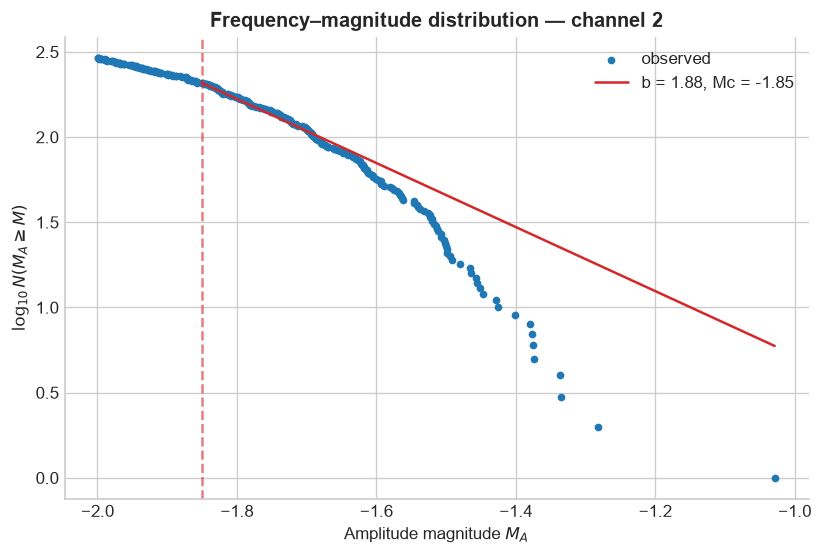

In [13]:
if B_VALUE_CHANNEL is None:
    B_VALUE_CHANNEL = selected_channels[0]
if B_VALUE_CHANNEL not in selected_channels:
    raise ValueError(f"B_VALUE_CHANNEL must be one of {selected_channels}.")

sample = accepted_events[accepted_events["channel"] == B_VALUE_CHANNEL]
amplitude = pd.to_numeric(sample["peak_to_peak"], errors="coerce").to_numpy(float)
amplitude = amplitude[np.isfinite(amplitude) & (amplitude > 0)]
magnitude = np.log10(amplitude / AMPLITUDE_REFERENCE) if len(amplitude) else np.array([])
b_value, mc, n_complete = estimate_b_value(amplitude, MAGNITUDE_BIN, MIN_EVENTS_FOR_B)

if len(magnitude):
    x_values = np.sort(np.unique(magnitude))
    cumulative = np.array([(magnitude >= value).sum() for value in x_values])
    fig, axis = plt.subplots(figsize=(8, 5))
    axis.scatter(x_values, np.log10(cumulative), s=13, label="observed")
    if np.isfinite(b_value):
        at_mc = max(1, (magnitude >= mc).sum())
        fit_x = np.linspace(mc, magnitude.max(), 100)
        fit_y = np.log10(at_mc) - b_value * (fit_x - mc)
        axis.plot(fit_x, fit_y, color="tab:red", label=f"b = {b_value:.2f}, Mc = {mc:.2f}")
        axis.axvline(mc, color="tab:red", ls="--", alpha=0.6)
    else:
        axis.text(0.03, 0.06, "Too few complete events for b", transform=axis.transAxes)
    axis.set(xlabel=r"Amplitude magnitude $M_A$", ylabel=r"$\log_{10}N(M_A\geq M)$",
             title=f"Frequency–magnitude distribution — channel {B_VALUE_CHANNEL}")
    axis.legend()
    plt.show()
else:
    print("No positive accepted amplitudes for this channel.")


## 11. Rolling b-value through deformation

Rolling estimates are calculated independently inside each continuous exposure interval, so they do not cross an unrecorded gap or move between physical windows. Each estimate is placed at the median event time. The controls below are independent of the controls in Point 8, avoiding hidden state between cells.


In [ ]:
def rolling_b_values(channel_events, channel_intervals, event_count, step):
    # Calculate fixed-event rolling b-values within continuous intervals.
    if event_count < MIN_EVENTS_FOR_B:
        raise ValueError("ROLLING_EVENTS must be at least MIN_EVENTS_FOR_B.")
    if step <= 0:
        raise ValueError("ROLLING_STEP must be positive.")

    rows = []
    for interval in channel_intervals.itertuples(index=False):
        interval_events = channel_events[
            (channel_events["window_index"] == interval.window_index)
            & (channel_events["onset_s"] >= interval.left_s)
            & (channel_events["onset_s"] < interval.right_s)
        ].sort_values("onset_s").reset_index(drop=True)

        for start in range(0, len(interval_events) - event_count + 1, step):
            part = interval_events.iloc[start:start + event_count]
            b, mc, n = estimate_b_value(part["peak_to_peak"], MAGNITUDE_BIN, MIN_EVENTS_FOR_B)
            rows.append({
                "window_index": int(interval.window_index), "window": interval.window,
                "interval_start_s": float(interval.left_s),
                "time_s": float(pd.to_numeric(part["onset_s"], errors="coerce").median()),
                "b": b, "Mc": mc, "events_above_Mc": int(n),
            })

    columns = ["window_index", "window", "interval_start_s", "time_s",
               "b", "Mc", "events_above_Mc"]
    result = pd.DataFrame(rows, columns=columns)
    for column in ["interval_start_s", "time_s", "b", "Mc"]:
        result[column] = pd.to_numeric(result[column], errors="coerce")
    return result


channel_events = accepted_events[accepted_events["channel"] == B_VALUE_CHANNEL].copy()
channel_intervals = exposure_intervals[exposure_intervals["channel"] == B_VALUE_CHANNEL].copy()
rolling = rolling_b_values(channel_events, channel_intervals, ROLLING_EVENTS, ROLLING_STEP)
print(f"Channel {B_VALUE_CHANNEL}: {len(channel_events):,} accepted events")
print(f"Finite rolling estimates: {rolling['b'].notna().sum():,}")


def plot_rolling_b(x_selection, y_column):
    mechanical_x, x_label = get_mechanical_x(x_selection)
    mechanical_y = pd.to_numeric(mechanical[y_column], errors="coerce").to_numpy(float)

    intervals = recorded_intervals.copy()
    intervals["left_x"] = time_to_x(intervals["left_s"], mechanical_x)
    intervals["right_x"] = time_to_x(intervals["right_s"], mechanical_x)

    plotted = rolling.copy()
    plotted["plot_x"] = time_to_x(plotted["time_s"].to_numpy(float), mechanical_x)
    finite = plotted[plotted["plot_x"].notna() & plotted["b"].notna()].copy()

    fig, (mechanical_axis, b_axis) = plt.subplots(
        2, 1, figsize=(13, 6.5), sharex=True, constrained_layout=True
    )
    valid = np.isfinite(mechanical_x) & np.isfinite(mechanical_y)
    mechanical_axis.plot(mechanical_x[valid], mechanical_y[valid], color="0.2", lw=1)
    mechanical_axis.set(ylabel=y_column, title="Mechanical evolution and rolling b-value")

    labelled = set()
    for item in intervals.itertuples(index=False):
        if not all(np.isfinite([item.left_x, item.right_x])):
            continue
        left, right = sorted([item.left_x, item.right_x])
        for axis in (mechanical_axis, b_axis):
            axis.axvspan(left, right, color=window_colors[item.window_index], alpha=0.14,
                         label=(item.window if axis is mechanical_axis
                                and item.window_index not in labelled else None))
        labelled.add(item.window_index)
    if labelled:
        mechanical_axis.legend(title="Recording window", fontsize=8, title_fontsize=8)

    if finite.empty:
        b_axis.text(0.5, 0.5,
                    f"No interval contains {ROLLING_EVENTS} events with a finite estimate.",
                    ha="center", va="center", transform=b_axis.transAxes)
    else:
        for (window_index, interval_start), segment in finite.groupby(
                ["window_index", "interval_start_s"], sort=True):
            segment = segment.sort_values("time_s")
            b_axis.plot(segment["plot_x"], segment["b"], marker="o", ms=4, lw=1.2,
                        color=window_colors.get(window_index, "tab:blue"))

    b_axis.set(ylabel="b-value proxy", xlabel=x_label,
               title=(f"Rolling b-value — channel {B_VALUE_CHANNEL}; "
                      f"{ROLLING_EVENTS} events; step {ROLLING_STEP}"))
    for axis in (mechanical_axis, b_axis):
        axis.grid(alpha=0.25)

    finite_bounds = intervals[["left_x", "right_x"]].to_numpy(float).ravel()
    finite_bounds = finite_bounds[np.isfinite(finite_bounds)]
    if finite_bounds.size:
        b_axis.set_xlim(finite_bounds.min(), finite_bounds.max())
    plt.show()


rolling_x_dropdown = widgets.Dropdown(
    options=x_axis_options, value=initial_x, description="X axis:",
    style={"description_width": "initial"}, layout=widgets.Layout(width="420px"),
)
rolling_y_dropdown = widgets.Dropdown(
    options=available_mechanical_columns, value=initial_y, description="Mechanical Y:",
    style={"description_width": "initial"}, layout=widgets.Layout(width="420px"),
)
display(widgets.HBox([rolling_x_dropdown, rolling_y_dropdown]),
        widgets.interactive_output(plot_rolling_b,
            {"x_selection": rolling_x_dropdown, "y_column": rolling_y_dropdown}))


TypeError: rolling_b_values() got an unexpected keyword argument 'ROLLING_EVENTS'

## 12. Activities and interpretation

### A — Verify exposure

Inspect `exposure` and `recorded_intervals`. Every shaded interval should correspond to chunks that were actually analyzed. With a legacy catalogue, explicitly add analyzed zero-event chunks before interpreting zeros in AE rate.

### B — Test the rate-bin choice

Choose different $\Delta t$ values for different window–channel pairs in Point 6. Identify which features remain stable and which are created or suppressed by bin width.

### C — Compare mechanics, rate, and amplitude

Plot against time and against a deformation variable. Ask whether increasing rate and large amplitudes occur together and whether they coincide with loading, inelastic deformation, or failure.

### D — Compare channels and windows

Do not sum channels automatically. Compare their timing and sensitivity while considering sensor position, coupling, gain, attenuation, and threshold.

### E — Interpret the b-value proxy cautiously

Compare global, window-specific, and rolling estimates. Record the event count, $M_c$, amplitude reference, magnitude-bin width, and detector settings.


## 13. Optional summary table

The exposure-normalized mean rate is calculated separately for every window and channel.


In [ ]:
window_summary = (ae_rate.groupby(["window_index", "window", "channel"], as_index=False)
                  .agg(accepted_AE=("count", "sum"),
                       analyzed_time_s=("exposure_s", "sum"),
                       maximum_binned_rate_hz=("ae_rate_hz", "max"),
                       minimum_delta_t_s=("requested_delta_t_s", "min"),
                       maximum_delta_t_s=("requested_delta_t_s", "max")))
window_summary["exposure_normalized_rate_hz"] = (
    window_summary["accepted_AE"] / window_summary["analyzed_time_s"]
)
display(window_summary)
